# Walmart Weekly Sales Analysis

## Problem Statement

A retail store that has multiple outlets across the country is facing issues in managing the inventory to match the demand with respect to supply.

### Dataset Information

The `walmart.csv` dataset contains **6435 rows and 8 columns**.

| Feature Name | Description |
|---|---|
| `Store` | Store number |
| `Date` | Week of sales |
| `Weekly_Sales` | Sales for the given store in that week |
| `Holiday_Flag` | Indicates if it is a holiday week |
| `Temperature` | Temperature on the day of the sale |
| `Fuel_Price` | Cost of fuel in the region |
| `CPI` | Consumer Price Index |
| `Unemployment` | Unemployment Rate |

---

## Objective

Perform **statistical analysis, Exploratory Data Analysis (EDA), outlier analysis, and handle missing values** to gain insights into the following:

### 1. Unemployment and Weekly Sales
- Are the weekly sales affected by the unemployment rate?
- If yes, which stores are suffering the most?

### 2. Seasonal Trends
- Do the weekly sales show a seasonal trend?
- If yes, when does the seasonal trend occur and what could be the reason?

### 3. Temperature and Weekly Sales
- Does temperature affect the weekly sales in any manner?

### 4. Consumer Price Index and Weekly Sales
- How is the Consumer Price Index affecting the weekly sales of various stores?

### 5. Store Performance
- Perform a statistical analysis of the stores according to the historical data.

### 6. Best and Worst Performing Stores
- Identify the worst-performing store.
- Determine how significant the difference is between the highest and lowest performing stores.

---

# Data Dictionary

| Column | Meaning |
|---|---|
| `Store` | Store number / identifier of the store |
| `Date` | Week of sales |
| `Weekly_Sales` | Sales generated by the store during that week |
| `Holiday_Flag` | Indicates whether the week is a holiday week (1 = Holiday, 0 = Non-Holiday) |
| `Temperature` | Temperature recorded during the week |
| `Fuel_Price` | Fuel price in the region during that week |
| `CPI` | Consumer Price Index for the region during that week |
| `Unemployment` | Unemployment rate in the region during that week |

---

## Main Variable of Interest

`Weekly_Sales`

The primary goal of the analysis is to understand the patterns in weekly sales and investigate how different factors such as **time, holidays, temperature, CPI, unemployment, and store differences** are associated with weekly sales.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_csv("/content/Walmart DataSet.csv")
df

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106
...,...,...,...,...,...,...,...,...
6430,45,28-09-2012,713173.95,0,64.88,3.997,192.013558,8.684
6431,45,05-10-2012,733455.07,0,64.89,3.985,192.170412,8.667
6432,45,12-10-2012,734464.36,0,54.47,4.000,192.327265,8.667
6433,45,19-10-2012,718125.53,0,56.47,3.969,192.330854,8.667


#EDA

In [ ]:
#Checking for nulls
df.isna().sum()
#NO Nulls

,0
Store,0
Date,0
Weekly_Sales,0
Holiday_Flag,0
Temperature,0
Fuel_Price,0
CPI,0
Unemployment,0


In [ ]:
#Checking for duplicates
df.duplicated().sum()
#No duplicates as well

np.int64(0)

In [ ]:
df.info()
#Date -> stored as an object -> Needs to be converted to date

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   object 
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 402.3+ KB


In [ ]:
df['Date']=pd.to_datetime(df['Date'],format="%d-%m-%Y")

In [ ]:
df.info() #-> now in datetime

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Store         6435 non-null   int64         
 1   Date          6435 non-null   datetime64[ns]
 2   Weekly_Sales  6435 non-null   float64       
 3   Holiday_Flag  6435 non-null   int64         
 4   Temperature   6435 non-null   float64       
 5   Fuel_Price    6435 non-null   float64       
 6   CPI           6435 non-null   float64       
 7   Unemployment  6435 non-null   float64       
dtypes: datetime64[ns](1), float64(5), int64(2)
memory usage: 402.3 KB


In [ ]:
df.describe()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
count,6435.000000,6435,6.435000e+03,6435.000000,6435.000000,6435.000000,6435.000000,6435.000000
mean,23.000000,2011-06-17 00:00:00,1.046965e+06,0.069930,60.663782,3.358607,171.578394,7.999151
min,1.000000,2010-02-05 00:00:00,2.099862e+05,0.000000,-2.060000,2.472000,126.064000,3.879000
25%,12.000000,2010-10-08 00:00:00,5.533501e+05,0.000000,47.460000,2.933000,131.735000,6.891000
50%,23.000000,2011-06-17 00:00:00,9.607460e+05,0.000000,62.670000,3.445000,182.616521,7.874000
75%,34.000000,2012-02-24 00:00:00,1.420159e+06,0.000000,74.940000,3.735000,212.743293,8.622000
max,45.000000,2012-10-26 00:00:00,3.818686e+06,1.000000,100.140000,4.468000,227.232807,14.313000
std,12.988182,NaN,5.643666e+05,0.255049,18.444933,0.459020,39.356712,1.875885


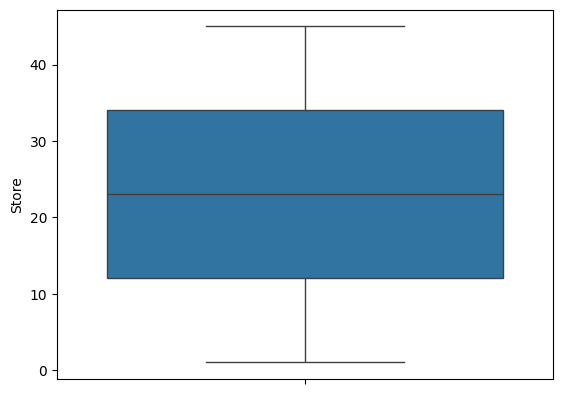

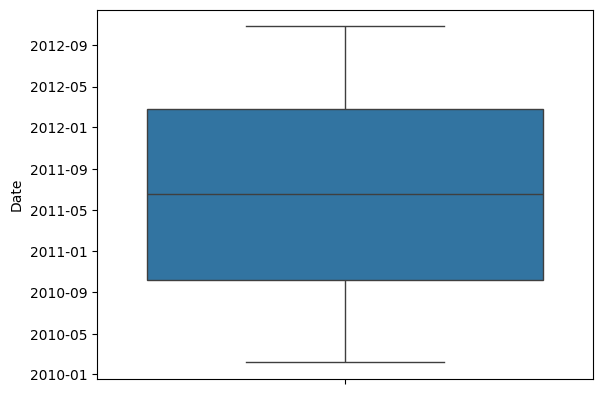

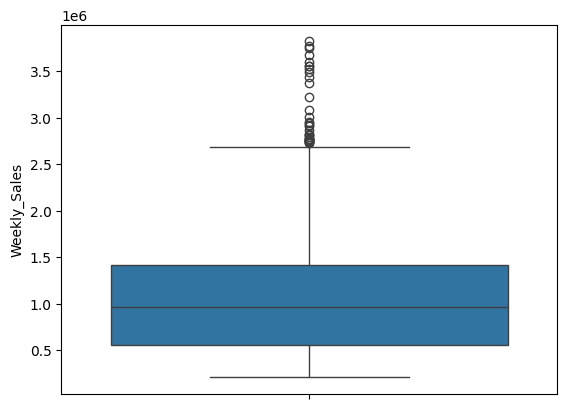

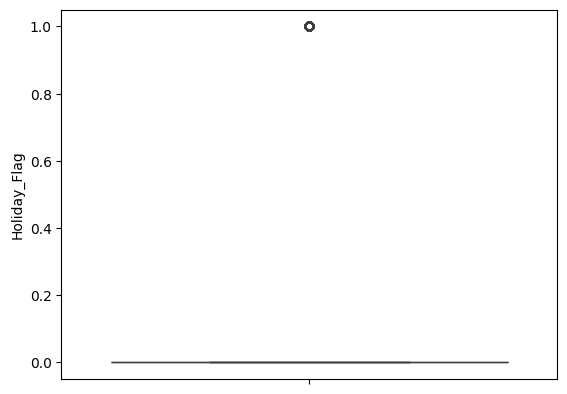

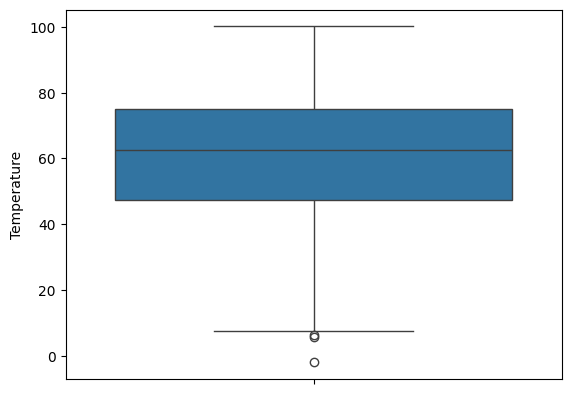

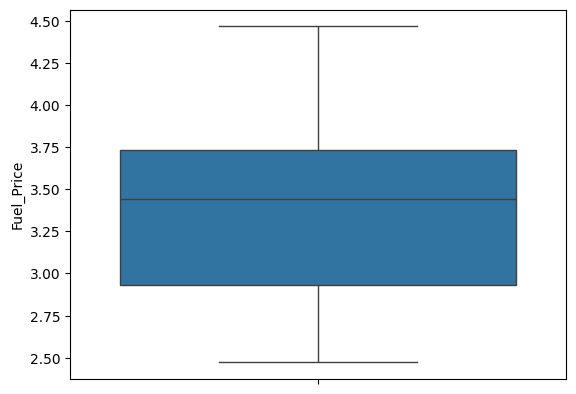

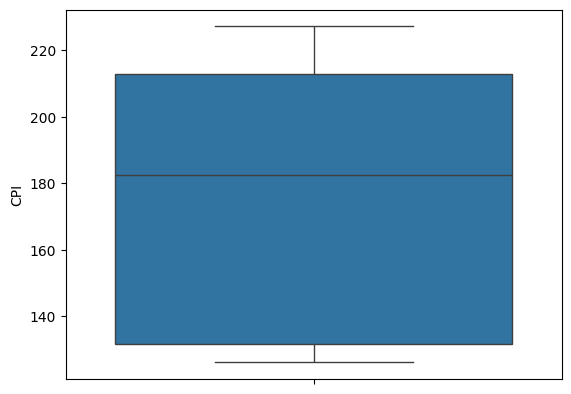

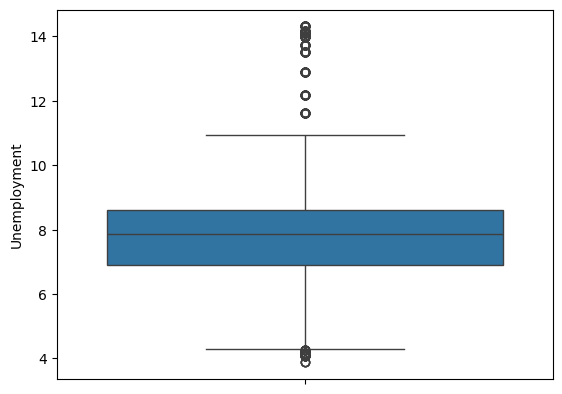

In [ ]:
#Outlier Analysis
for col in df.columns:
  if df[col].dtype != 'object':
    sns.boxplot(df[col])
    plt.show()

In [ ]:
#Outlier Analysis:
for col in ['Weekly_Sales','Temperature','Unemployment']:
  Q1=df[col].quantile(0.25)
  Q3=df[col].quantile(0.75)
  IQR=(Q3-Q1)
  lb=Q1-1.5*IQR
  ub=Q3+1.5*IQR
  print("Results for column:",col)
  req_df=df[(df[col]<=lb) | (df[col]>=ub)].sort_values(by=col,ascending=True)
  print(req_df)
  print(req_df.shape)

Results for column: Weekly_Sales
      Store       Date  Weekly_Sales  Holiday_Flag  Temperature  Fuel_Price  \
761       6 2010-12-24    2727575.18             0        55.07       2.886   
3192     23 2010-12-24    2734277.10             0        22.96       3.150   
3816     27 2011-12-23    2739019.75             0        41.59       3.587   
474       4 2010-12-17    2740057.14             0        46.57       2.884   
2761     20 2010-12-10    2752122.08             0        24.27       3.109   
1813     13 2011-12-16    2760346.71             0        27.85       3.282   
2814     20 2011-12-16    2762816.65             0        37.16       3.413   
1904     14 2010-12-17    2762861.41             0        30.51       3.140   
1758     13 2010-11-26    2766400.05             1        28.22       2.830   
526       4 2011-12-16    2771397.17             0        36.44       3.149   
1761     13 2010-12-17    2771646.81             0        35.21       2.842   
471       4 2010-11

### Outlier Analysis — Conclusion

- **Weekly_Sales:** IQR flagged several unusually high values, mostly around November–December. These may represent genuine seasonal/holiday sales peaks, so they were **retained**.
- **Temperature:** Three low values were flagged (`-2.06`, `5.54`, `6.23`). These are unusual but physically plausible, so they were **retained**.
- **Unemployment:** 481 observations were flagged by the IQR rule. The values appear plausible, and being an IQR outlier does not imply incorrect data. Therefore, they were **retained**.

**Overall:**

> IQR identifies statistically unusual observations, not necessarily erroneous data. Since no clear data-entry or measurement errors were identified, the observations were retained for further analysis.

From the above data, all the supposed outliers do not look abnormally large or small.
Hence, to preserve information and some exceptional performers for better analysis, we do not remove the above outliers.


---------- EDA Closed -----------

### 1a. If the weekly sales are affected by the unemployment rate, if yes - which stores are suffering the most?

In [ ]:
#Pearson Coefficient: Overall Weekly_Sales vs Unemployment Rate
df[['Weekly_Sales','Unemployment']].corr(method='pearson')
# -0.11 correlation coefficient -> weak negative correlation

,Weekly_Sales,Unemployment
Weekly_Sales,1.000000,-0.106176
Unemployment,-0.106176,1.000000


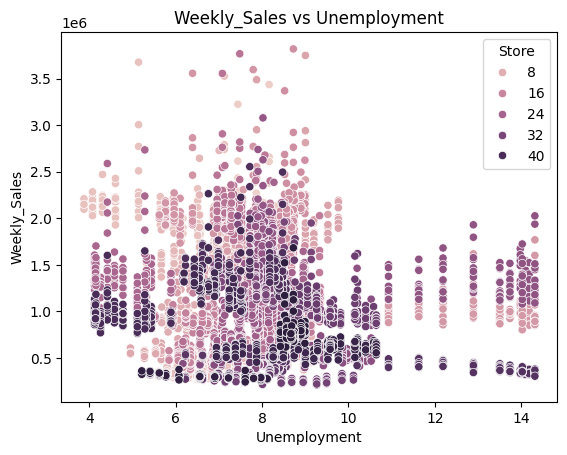

In [ ]:
#Scatter plot: Weekly_Sales vs Unemployment Rate
sns.scatterplot(data=df,x='Unemployment',y='Weekly_Sales',hue='Store')
plt.title('Weekly_Sales vs Unemployment')
plt.show()

/tmp/ipykernel_2173/2410907759.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  store_corr = df.groupby('Store').apply(lambda x: x['Unemployment'].corr(x['Weekly_Sales']))


<Axes: ylabel='Store'>

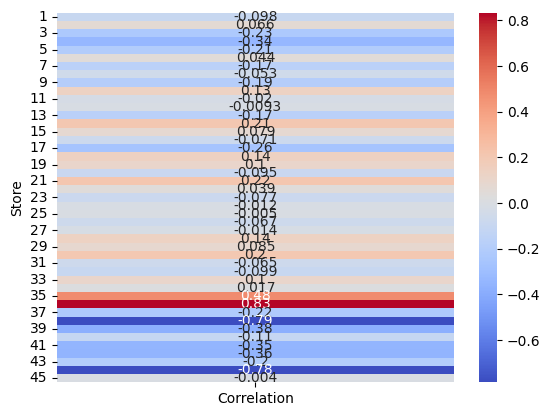

In [ ]:
# Store-wise correlation
store_corr = df.groupby('Store').apply(lambda x: x['Unemployment'].corr(x['Weekly_Sales']))
store_corr = store_corr.to_frame(name='Correlation')
sns.heatmap(store_corr, annot=True, cmap='coolwarm')

In [ ]:
#From the above, it is clear that very few stores show a strong relationship with the
#unemployment rate, the strength of relationship also varies from store to store

In [ ]:
store_corr['Absolute_Correlation'] = store_corr['Correlation'].abs()

store_corr.sort_values(by='Absolute_Correlation',ascending=False).head(5)

,Correlation,Absolute_Correlation
Store,,
36,0.833734,0.833734
38,-0.785290,0.785290
44,-0.780076,0.780076
35,0.483865,0.483865
39,-0.384681,0.384681


In [ ]:
#The five most affected stores by unemployment rate:
# 36,35 -> stronger positive correlation
# 38,44,39 -> stronger nnegative relation

#### Conclusion

The Pearson correlation coefficient between **Unemployment** and **Weekly_Sales** is approximately **-0.11**, indicating a **weak negative linear association** overall.

However, the store-wise correlations vary considerably. Stores **38, 44, 39, 42, and 41** show the strongest negative associations, with Stores **38 and 44** having correlations of approximately **-0.79** and **-0.78**, respectively.

Thus, these stores show the **strongest negative relationship between unemployment and weekly sales** in the dataset. However, correlation indicates **association and does not establish causation**.

### b. If the weekly sales show a seasonal trend, when and what could be the reason?

In [ ]:
#Weekly aggregates of sales for all stores combined
week_sales=df.groupby('Date')['Weekly_Sales'].sum().reset_index()
week_sales

,Date,Weekly_Sales
0,2010-02-05,49750740.50
1,2010-02-12,48336677.63
2,2010-02-19,48276993.78
3,2010-02-26,43968571.13
4,2010-03-05,46871470.30
...,...,...
138,2012-09-28,43734899.40
139,2012-10-05,47566639.31
140,2012-10-12,46128514.25
141,2012-10-19,45122410.57


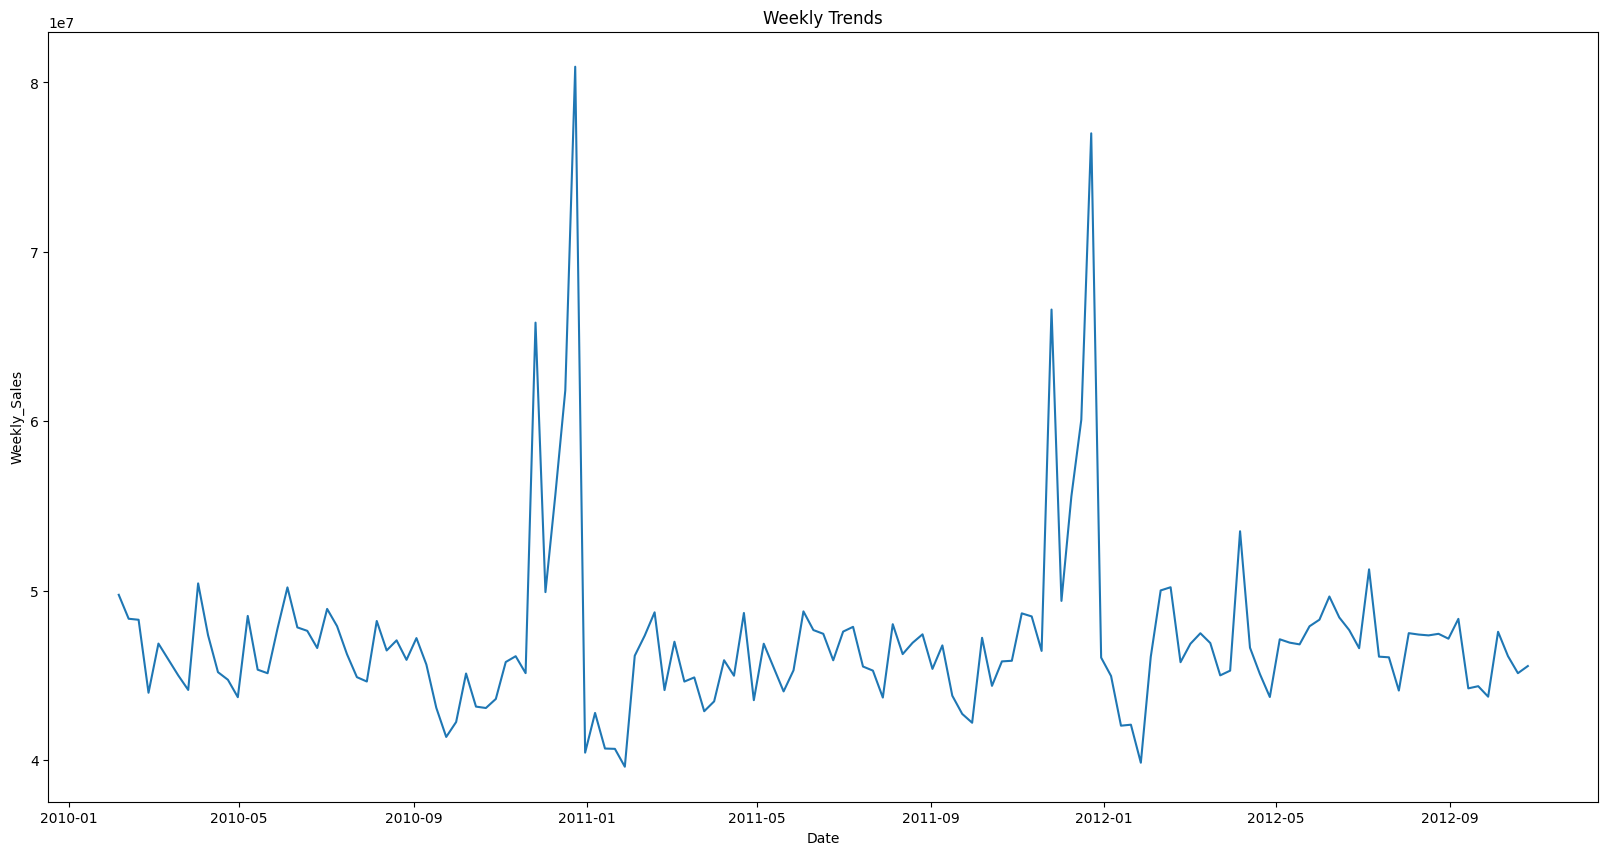

In [ ]:
#Plotting overall weekly sales
plt.figure(figsize=(20,10))
sns.lineplot(data=week_sales,x='Date',y='Weekly_Sales')
plt.title('Weekly Trends')
plt.show()

In [ ]:
#The above seems to show a specific pattern, a spike in sales that occurs just before the
# ending of the year and a drop at the beginning of the new year(all stores combined)

In [ ]:
# Extract year and month
week_sales['Year'] = week_sales['Date'].dt.year
week_sales['Month'] = week_sales['Date'].dt.month

# Aggregate sales by year and month
month_sales = (week_sales.groupby(['Year', 'Month'])['Weekly_Sales'].sum().reset_index())

month_sales

,Year,Month,Weekly_Sales
0,2010,2,1.903330e+08
1,2010,3,1.819198e+08
2,2010,4,2.314124e+08
3,2010,5,1.867109e+08
4,2010,6,1.922462e+08
5,2010,7,2.325801e+08
6,2010,8,1.876401e+08
7,2010,9,1.772679e+08
8,2010,10,2.171618e+08
9,2010,11,2.028534e+08


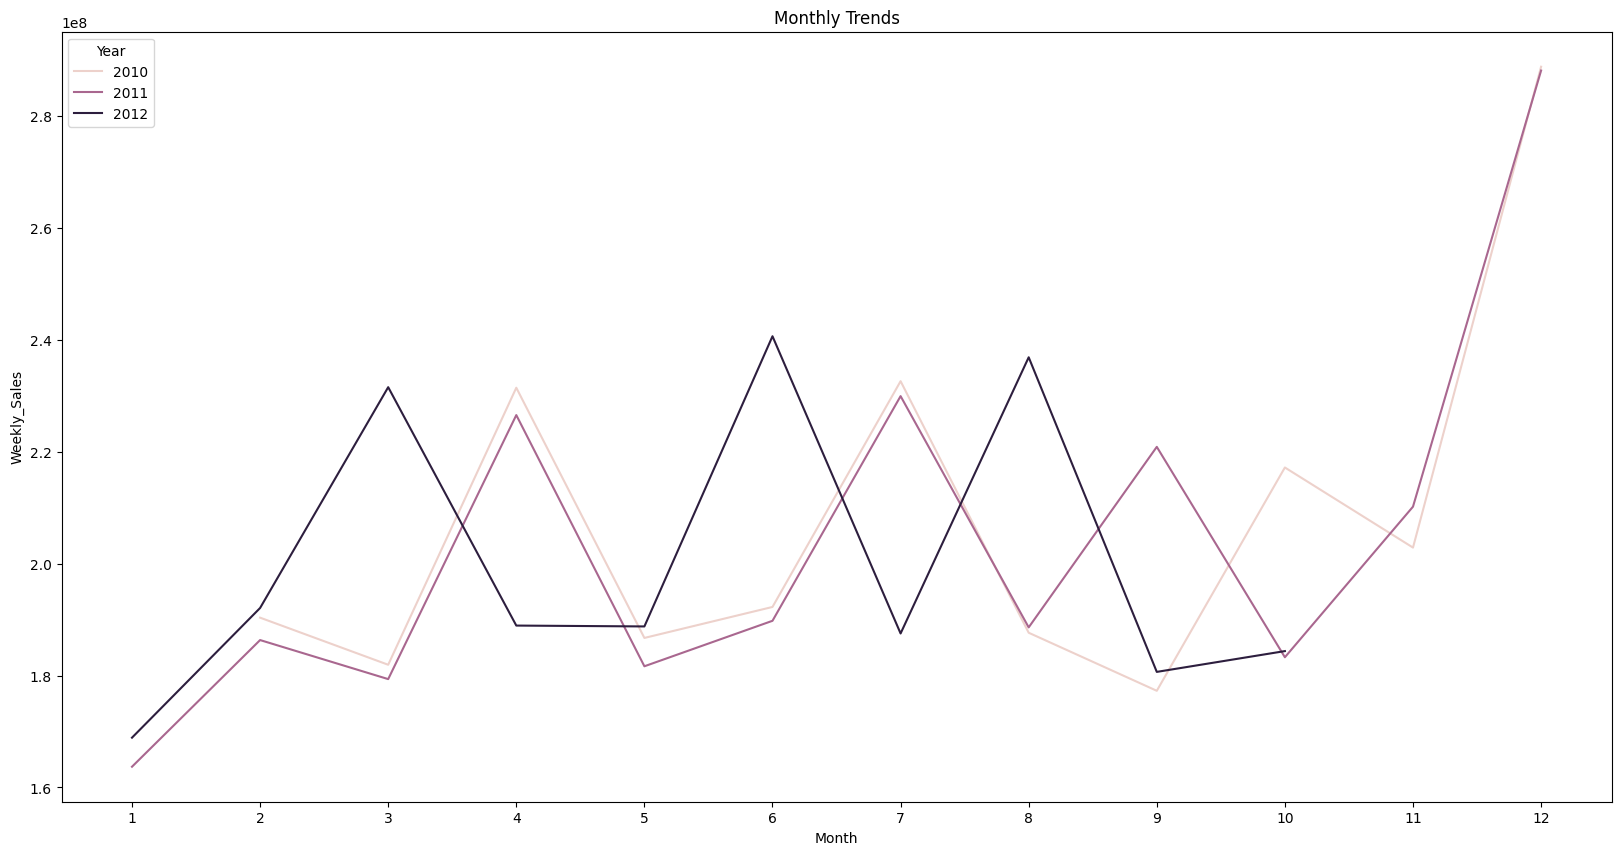

In [ ]:
#Plot overall monthly sales
plt.figure(figsize=(20,10))
sns.lineplot(data=month_sales,x='Month',y='Weekly_Sales',hue='Year')
plt.title('Monthly Trends')
plt.xticks(range(1,13))
plt.show()

In [ ]:
#From the above, it is clear patterns keep repeating on a yearly basis, spikes at
# year end and lows at beginning and then following a wave like pattern(all stores combined)

In [ ]:
#Sales per store per week
store_weekly_sales = df.groupby(['Date', 'Store'])['Weekly_Sales'].sum().reset_index()
store_weekly_sales

,Date,Store,Weekly_Sales
0,2010-02-05,1,1643690.90
1,2010-02-05,2,2136989.46
2,2010-02-05,3,461622.22
3,2010-02-05,4,2135143.87
4,2010-02-05,5,317173.10
...,...,...,...
6430,2012-10-26,41,1316542.59
6431,2012-10-26,42,514756.08
6432,2012-10-26,43,587603.55
6433,2012-10-26,44,361067.07


In [ ]:
#Formatting the store_weekly_sales
store_weekly_sales = store_weekly_sales.pivot(index='Store',columns='Date',values='Weekly_Sales')
store_weekly_sales

Date,2010-02-05,2010-02-12,2010-02-19,2010-02-26,2010-03-05,2010-03-12,2010-03-19,2010-03-26,2010-04-02,2010-04-09,...,2012-08-24,2012-08-31,2012-09-07,2012-09-14,2012-09-21,2012-09-28,2012-10-05,2012-10-12,2012-10-19,2012-10-26
Store,,,,,,,,,,,,,,,,,,,,,
1,1643690.90,1641957.44,1611968.17,1409727.59,1554806.68,1439541.59,1472515.79,1404429.92,1594968.28,1545418.53,...,1494122.38,1582083.40,1661767.33,1517428.87,1506126.06,1437059.26,1670785.97,1573072.81,1508068.77,1493659.74
2,2136989.46,2137809.50,2124451.54,1865097.27,1991013.13,1990483.78,1946070.88,1750197.81,2066187.72,1954689.21,...,1876788.15,1947083.30,1898777.07,1814806.63,1829415.67,1746470.56,1998321.04,1900745.13,1847990.41,1834458.35
3,461622.22,420728.96,421642.19,407204.86,415202.04,384200.69,375328.59,359949.27,423294.40,415870.28,...,412449.67,408838.73,408229.73,407589.16,414392.09,389813.02,443557.65,410804.39,424513.08,405432.70
4,2135143.87,2188307.39,2049860.26,1925728.84,1971057.44,1894324.09,1897429.36,1762539.30,1979247.12,1818452.72,...,2125241.68,2081181.35,2125104.72,2117854.60,2119438.53,2027620.23,2209835.43,2133026.07,2097266.85,2149594.46
5,317173.10,311825.70,303447.57,270281.63,288855.71,297293.59,281706.41,273282.97,331406.00,328020.49,...,320831.36,344642.01,350648.91,299800.67,307306.76,310141.68,343048.29,325345.41,313358.15,319550.77
6,1652635.10,1606283.86,1567138.07,1432953.21,1601348.82,1558621.36,1693058.91,1472033.38,1770333.90,1667181.82,...,1501095.49,1577439.81,1608077.01,1375166.86,1425603.65,1369131.46,1518177.71,1459396.84,1436883.99,1431426.34
7,496725.44,524104.92,506760.54,496083.24,491419.55,480452.10,574450.23,514731.60,561145.14,484263.25,...,609099.37,586467.16,597876.55,541120.20,530842.25,525545.76,505830.56,503463.93,516424.83,495543.28
8,1004137.09,994801.40,963960.37,847592.11,881503.95,860336.16,839911.00,772539.12,914500.91,916033.92,...,936373.65,976137.73,932160.37,883569.38,857796.45,884724.41,976436.02,927511.99,900309.75,891671.44
9,549505.55,552677.48,511327.90,473773.27,507297.88,494145.80,485744.61,484946.56,545206.32,529384.31,...,572887.78,576879.15,565812.29,523427.35,533756.88,516361.06,606755.30,558464.80,542009.46,549731.49


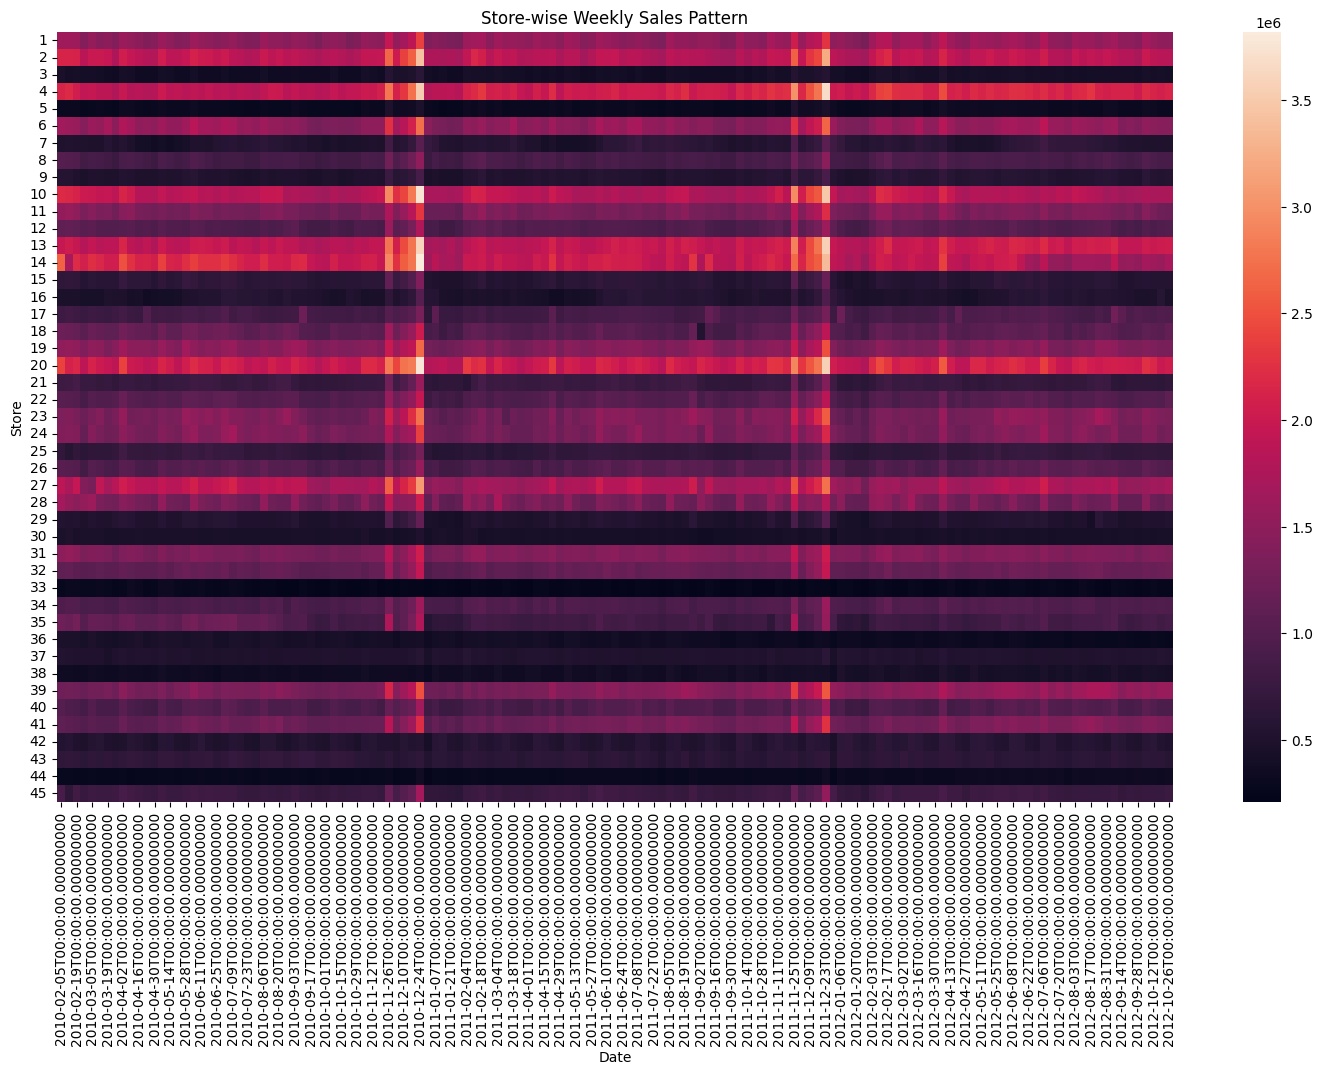

In [ ]:
plt.figure(figsize=(18, 10))

sns.heatmap(store_weekly_sales)

plt.xlabel('Date')
plt.ylabel('Store')
plt.title('Store-wise Weekly Sales Pattern')
plt.show()

In [ ]:
#From the above, we can see strips of high sales for each store during the months of november
#and december every year

In [ ]:
#Effect of holidays
holiday_sales = df.groupby('Holiday_Flag')['Weekly_Sales'].mean()

print(holiday_sales)
#A little higher sales during holiday weeks

Holiday_Flag
0    1.041256e+06
1    1.122888e+06
Name: Weekly_Sales, dtype: float64


In [ ]:
spike = (holiday_sales.iloc[1] - holiday_sales.iloc[0]) / holiday_sales.iloc[0]

print(f"Holiday sales increase: {spike:.2%}")

Holiday sales increase: 7.84%


In [ ]:
lag_52 = week_sales['Weekly_Sales'].autocorr(lag=52)
print(f"Lag-52 Autocorrelation: {lag_52:.2f}")

Lag-52 Autocorrelation: 0.93


In [ ]:
#ADF test
from statsmodels.tsa.stattools import adfuller

result = adfuller(week_sales['Weekly_Sales'])

print(f"ADF Statistic: {result[0]:.2f}")
print(f"p-value: {result[1]:.4f}")

ADF Statistic: -5.91
p-value: 0.0000


/tmp/ipykernel_2173/2474214671.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(week_sales['Weekly_Sales'])


#### Conclusion

The weekly sales show a clear seasonal pattern, with sales generally peaking around November–December and declining sharply in January.

The Lag-52 autocorrelation is 0.93, indicating a strong similarity between sales separated by one year and supporting the presence of an annual seasonal pattern.

Holiday weeks also have higher average weekly sales (1.123 million) compared with non-holiday weeks (1.041 million), suggesting that holiday periods may contribute to the observed sales peaks(an increase of 7.84%)

The ADF test gives a p-value of 0.0000, indicating that the weekly sales series is stationary according to the ADF test. However, the ADF test is a stationarity test and does not by itself establish seasonality.

Possible reasons for the seasonal peaks include increased holiday shopping, promotions, and higher consumer spending during the holiday period.

### c. Does temperature affect the weekly sales in any manner?

In [ ]:
#Pearson Coefficient: Overall Weekly_Sales vs Temperature
df[['Weekly_Sales','Temperature']].corr(method='pearson')
# a weak correlation constant of -0.06 -> Weak negative correlation

,Weekly_Sales,Temperature
Weekly_Sales,1.00000,-0.06381
Temperature,-0.06381,1.00000


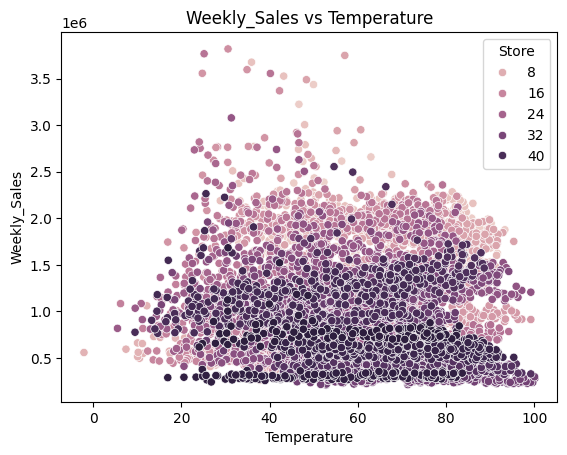

In [ ]:
#Scatter plot: Weekly_Sales vs Temperature
sns.scatterplot(data=df,x='Temperature',y='Weekly_Sales',hue='Store')
plt.title("Weekly_Sales vs Temperature")
plt.show()

/tmp/ipykernel_2173/3775102171.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  store_corr = df.groupby('Store').apply(lambda x: x['Temperature'].corr(x['Weekly_Sales']))


<Axes: ylabel='Store'>

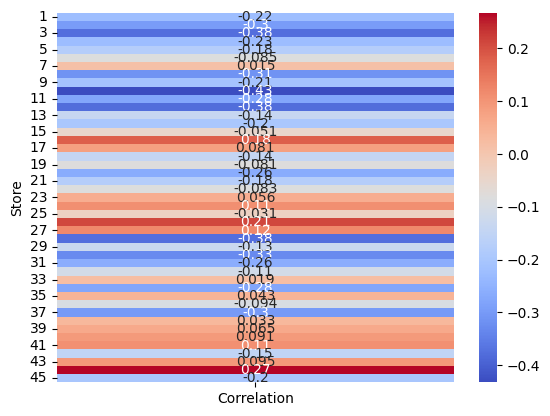

In [ ]:
# Store-wise correlation
store_corr = df.groupby('Store').apply(lambda x: x['Temperature'].corr(x['Weekly_Sales']))
store_corr = store_corr.to_frame(name='Correlation')
sns.heatmap(store_corr, annot=True, cmap='coolwarm')

In [ ]:
store_corr['Absolute_Correlation'] = store_corr['Correlation'].abs()

store_corr.sort_values(by='Absolute_Correlation',ascending=False).head(5)

,Correlation,Absolute_Correlation
Store,,
10,-0.432569,0.432569
12,-0.379416,0.379416
3,-0.377524,0.377524
28,-0.376506,0.376506
30,-0.330816,0.330816


In [ ]:
#From the above, it is clear that there exists weak negative correlation between the sales and the temperature
#The coefficient also varies significantly from store to store

#### Conclusion

The Pearson correlation coefficient between Temperature and Weekly_Sales is approximately **-0.06**, indicating a **very weak negative linear association** overall.

The store-wise correlations vary considerably. Stores **10, 12, 3, 28, and 30** show the strongest negative associations, with the maximum absolute value recording to be **0.43** for store **10**

### Overall, temperature doesn't seem to have significant effects on weekly sales

### d. How is the Consumer Price index affecting the weekly sales of various stores?

In [ ]:
#Pearson Coefficient: Overall Weekly_Sales vs CPI
df[['Weekly_Sales','CPI']].corr(method='pearson')
#A very weak negative correlation constant of -0.07

,Weekly_Sales,CPI
Weekly_Sales,1.000000,-0.072634
CPI,-0.072634,1.000000


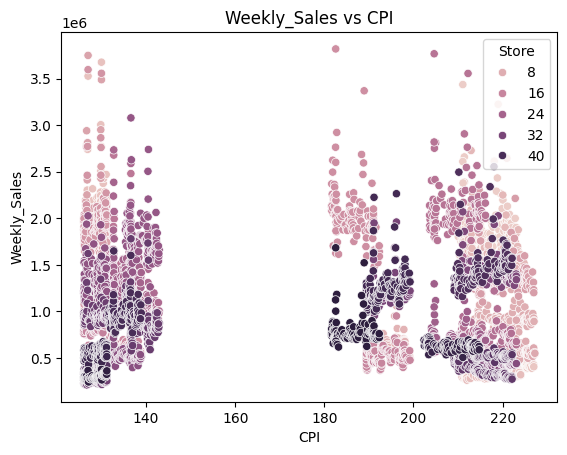

In [ ]:
#Scatter plot: Weekly_Sales vs CPI
sns.scatterplot(data=df,x='CPI',y='Weekly_Sales',hue='Store')
plt.title("Weekly_Sales vs CPI")
plt.show()

In [ ]:
# Spearman correlation
spearman_corr = df['CPI'].corr(df['Weekly_Sales'], method='spearman')

print("Spearman correlation:", spearman_corr)

Spearman correlation: -0.05504003807440306


/tmp/ipykernel_2173/525241277.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  store_corr = df.groupby('Store').apply(lambda x: x['CPI'].corr(x['Weekly_Sales'],method='spearman'))


<Axes: ylabel='Store'>

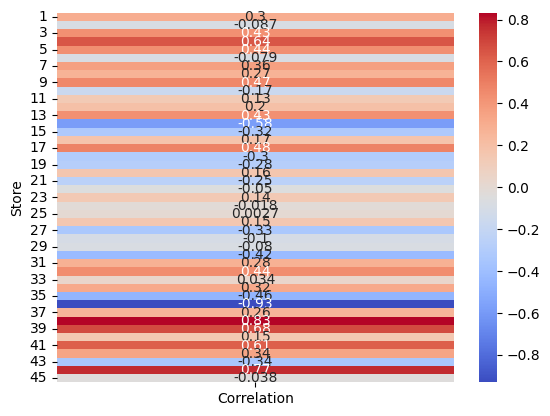

In [ ]:
# Store-wise correlation
store_corr = df.groupby('Store').apply(lambda x: x['CPI'].corr(x['Weekly_Sales'],method='spearman'))
store_corr = store_corr.to_frame(name='Correlation')
sns.heatmap(store_corr, annot=True, cmap='coolwarm')

/tmp/ipykernel_2173/934174917.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  store_corr = df.groupby('Store').apply(lambda x: x['CPI'].corr(x['Weekly_Sales']))


<Axes: ylabel='Store'>

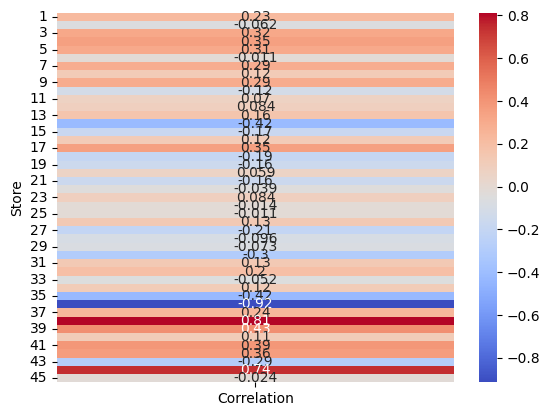

In [ ]:
# Store-wise correlation
store_corr = df.groupby('Store').apply(lambda x: x['CPI'].corr(x['Weekly_Sales']))
store_corr = store_corr.to_frame(name='Correlation')
sns.heatmap(store_corr, annot=True, cmap='coolwarm')

##### Results for Pearson and Spearman Coefficient are similar

In [ ]:
store_corr['Absolute_Correlation'] = store_corr['Correlation'].abs()

store_corr.sort_values(by='Absolute_Correlation',ascending=False).head(5)

,Correlation,Absolute_Correlation
Store,,
36,-0.915095,0.915095
38,0.812837,0.812837
44,0.740150,0.740150
39,0.428043,0.428043
35,-0.424107,0.424107


#### Conclusion

The store-wise Pearson correlation analysis shows that the relationship between **CPI** and **Weekly_Sales** varies considerably across stores.

**Store 36** shows the strongest negative correlation, with a coefficient of approximately **-0.92**, indicating a very strong inverse association between CPI and Weekly_Sales. This means that higher CPI values are associated with lower weekly sales for Store 36.

In contrast, **Store 38** shows a strong positive correlation of approximately **+0.84**, while **Store 44** shows a strong positive correlation of approximately **+0.74**. This indicates that higher CPI values are associated with higher weekly sales for these stores.

Thus, the relationship between CPI and Weekly_Sales is not consistent across all stores. However, correlation indicates **association and does not establish causation**.

### e. Top performing stores according to the historical data.

In [ ]:
#Aggregated sum of the weekly sales of each store(over time)
store_sales=df.groupby('Store')['Weekly_Sales'].sum()
store_sales.sort_values(ascending=False)

,Weekly_Sales
Store,
20,3.013978e+08
4,2.995440e+08
14,2.889999e+08
13,2.865177e+08
2,2.753824e+08
10,2.716177e+08
27,2.538559e+08
6,2.237561e+08
1,2.224028e+08


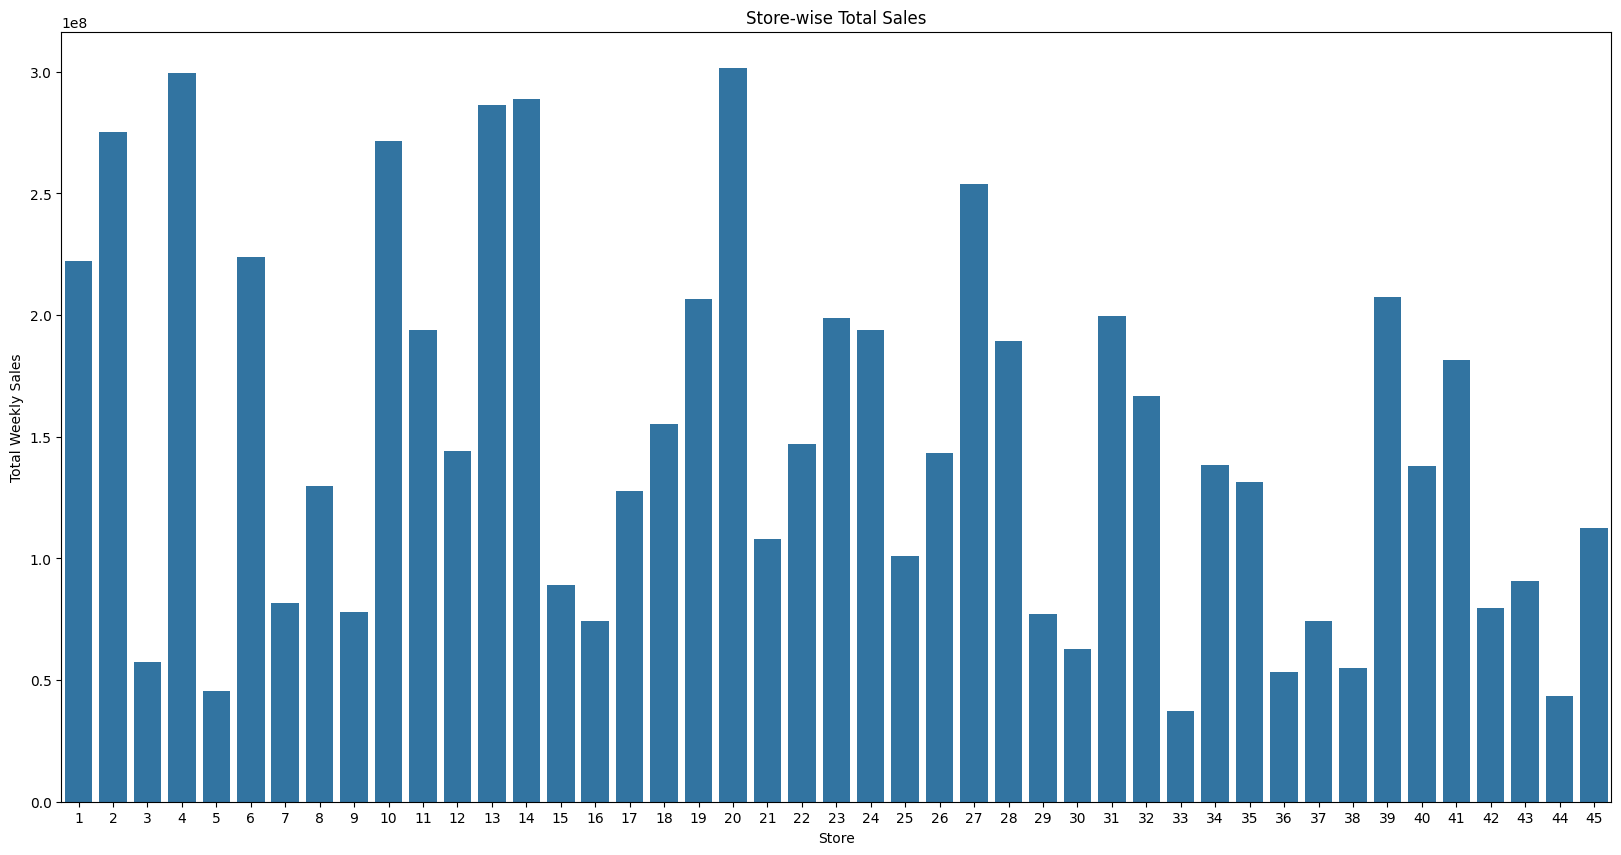

In [ ]:
#plotting the historically aggregated sales per store
plt.figure(figsize=(20,10))
sns.barplot(x=store_sales.index, y=store_sales.values) #we're using a series so index and values

plt.xlabel('Store')
plt.ylabel('Total Weekly Sales')
plt.title('Store-wise Total Sales')
plt.show()

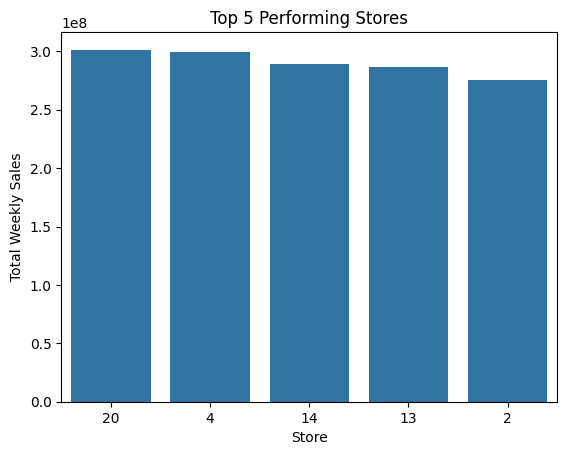

In [ ]:
#Top 5 stores
top_stores = store_sales.sort_values(ascending=False).head(5)

sns.barplot(x=top_stores.index, y=top_stores.values,order=top_stores.index)

plt.xlabel('Store')
plt.ylabel('Total Weekly Sales')
plt.title('Top 5 Performing Stores')
plt.show()

In [ ]:
#Top 5 stores and their sales
store_sales.sort_values(ascending=False).head(5).map(lambda x: f'{x:,.2f}')

,Weekly_Sales
Store,
20,"301,397,792.46"
4,"299,543,953.38"
14,"288,999,911.34"
13,"286,517,703.80"
2,"275,382,440.98"


#### Conclusion
Hence from the above, stores **20,4,14,13,2** are the best performing stores, considering the historically aggregated weekly sales data, making the top 5 highest sales

### f. The worst performing store, and how significant is the difference between the highest and lowest performing stores.

In [ ]:
#Aggregated sum of the weekly sales of each store(over time)
store_sales=df.groupby('Store')['Weekly_Sales'].sum()
store_sales.sort_values(ascending=True)

,Weekly_Sales
Store,
33,3.716022e+07
44,4.329309e+07
5,4.547569e+07
36,5.341221e+07
38,5.515963e+07
3,5.758674e+07
30,6.271689e+07
37,7.420274e+07
16,7.425243e+07


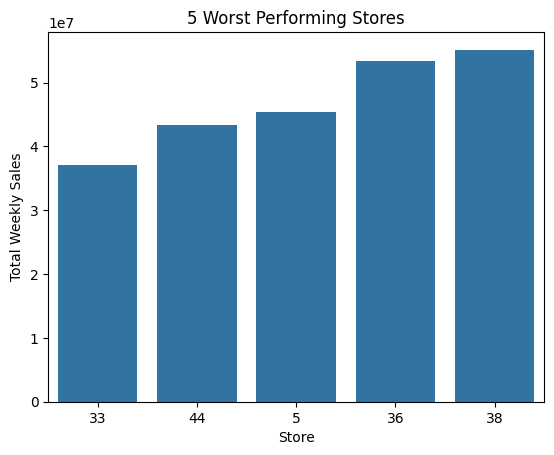

In [ ]:
# Worst performing 5 stores

bottom_stores = store_sales.sort_values(ascending=True).head(5)

sns.barplot(x=bottom_stores.index, y=bottom_stores.values,order=bottom_stores.index)

plt.xlabel('Store')
plt.ylabel('Total Weekly Sales')
plt.title('5 Worst Performing Stores')
plt.show()

In [ ]:
#Performance difference
highest = store_sales.max()
lowest = store_sales.min()

difference = highest - lowest

print("Highest sales:", highest)
print("Lowest sales:", lowest)
print("Difference:", difference)

Highest sales: 301397792.46
Lowest sales: 37160221.96
Difference: 264237570.49999997


In [ ]:
#Relative performance percentage
percentage_difference = ((highest - lowest) / lowest) * 100

print("Percentage difference:", percentage_difference)

Percentage difference: 711.0764052605243


#### Conclusion

**Store 33** is the worst-performing store based on total historical Weekly_Sales, with approximately **37.16 million** in sales. In comparison, **Store 20** is the highest-performing store, with approximately **301.40 million** in sales.

The difference between the highest- and lowest-performing stores is approximately **264.24 million**, with the highest-performing store having about **711% more sales** than the lowest-performing store.

This indicates a substantial difference in total historical sales performance across the stores.